Dataset:
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc

Missing values:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

Class distribution:
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

Random Forest Train Accuracy: 1.0
Random Forest Test Accuracy: 0.9788


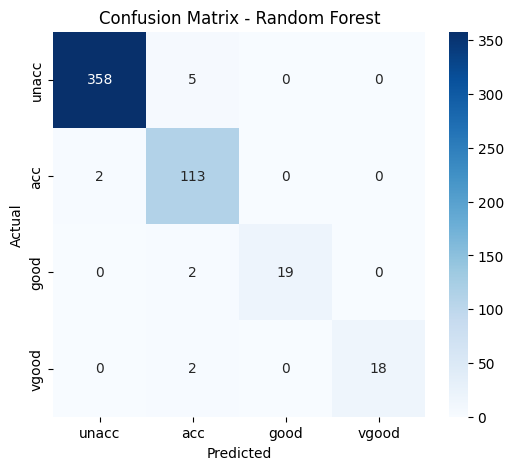

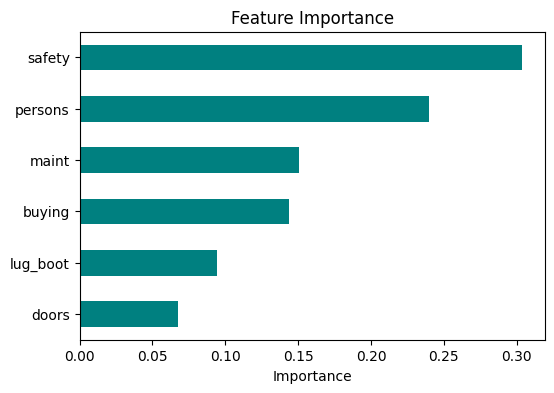


Single Decision Tree Test Accuracy: 0.9827
Random Forest with   1 trees: Test Accuracy = 0.8709
Random Forest with  10 trees: Test Accuracy = 0.9672
Random Forest with  50 trees: Test Accuracy = 0.9769
Random Forest with 100 trees: Test Accuracy = 0.9788
Random Forest with 200 trees: Test Accuracy = 0.9827

5-fold Cross-validation Accuracy: 0.8212 (+/- 0.0531 )

Predicted class for new car: vgood


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Load dataset
names = ['buying', 'maint', 'doors', 'persons',
         'lug_boot', 'safety', 'class']

df = pd.read_csv("car_evaluation.csv", header=None, names=names)

print("Dataset:")
print(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df['class'].value_counts())

# 2. Encode categorical features
order = {
    'buying': ['low', 'med', 'high', 'vhigh'],
    'maint': ['low', 'med', 'high', 'vhigh'],
    'doors': ['2', '3', '4', '5more'],
    'persons': ['2', '4', 'more'],
    'lug_boot': ['small', 'med', 'big'],
    'safety': ['low', 'med', 'high']
}

features = list(order.keys())

encoder = OrdinalEncoder(
    categories=[order[c] for c in features]
)

X = encoder.fit_transform(df[features])
y = df['class']

# 3. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 4. Train Random Forest
rf = RandomForestClassifier(
    n_estimators=100, random_state=42
)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

print("\nRandom Forest Train Accuracy:",
      round(rf.score(X_train, y_train), 4))

print("Random Forest Test Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

# 5. Confusion matrix
labels = ['unacc', 'acc', 'good', 'vgood']

cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=labels, yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")
plt.show()

# 6. Feature importance
importance = pd.Series(
    rf.feature_importances_, index=features
).sort_values()

importance.plot(kind='barh', figsize=(6, 4), color='teal')

plt.title("Feature Importance")
plt.xlabel("Importance")
plt.show()

# 7. Compare Decision Tree and Random Forest
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

print("\nSingle Decision Tree Test Accuracy:",
      round(dt.score(X_test, y_test), 4))

for n in [1, 10, 50, 100, 200]:

    model = RandomForestClassifier(
        n_estimators=n, random_state=42
    )

    model.fit(X_train, y_train)

    print(f"Random Forest with {n:3d} trees: Test Accuracy = "
          f"{model.score(X_test, y_test):.4f}")

# 8. 5-fold Cross-validation
scores = cross_val_score(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X, y, cv=5
)

print("\n5-fold Cross-validation Accuracy:",
      round(scores.mean(), 4), "(+/-", round(scores.std(), 4), ")")

# 9. Predict a new car
new_car = pd.DataFrame(
    [['low', 'low', '4', '4', 'big', 'high']],
    columns=features
)

new_car_encoded = encoder.transform(new_car)

print("\nPredicted class for new car:",
      rf.predict(new_car_encoded)[0])